# Paso 0: calibración del ambiente (sin entrenar)

**He(RL)l Kitchen v2.** Antes de entrenar DQN y PPO fijamos con datos los valores marcados como *(propuesta)* en el diseño (`docs/env_design.md`, sección 4.2). Solo se usan políticas escritas a mano, así que todo corre en minutos de CPU.

Todas las corridas usan las **seeds de validación** (`20000 + i`); las de prueba quedan reservadas para el reporte.

| Criterio | Pregunta |
|---|---|
| 1. Costo de probar | ¿Con qué costo la mejor frecuencia de prueba queda *en medio* (ni "nunca" ni "siempre")? |
| 2. Rango de σ_obs | ¿Entre qué ruidos la vista pasa de "casi alcanza" a "casi no sirve"? |
| 3. N por defecto | ¿Cuántas órdenes hay en la cola el 90 % del tiempo? |
| 4. Priorizar importa | ¿Una heurística que elige órdenes (EDF) supera claramente a la FIFO? |
| 5. Dificultad | ¿FIFO supera a la aleatoria sin acercarse al 100 % a tiempo? |

**Cómo correrlo**

- **Local:** con el entorno virtual activo, abrir este notebook desde `notebooks/` y ejecutar todo.
- **Google Colab:** abrir el notebook (desde GitHub o subiéndolo), poner en `BRANCH` la rama que se quiere correr y ejecutar todo. La primera celda clona el repo (o lo actualiza si ya estaba) e instala solo lo que Colab no trae.

Las tablas y figuras se guardan en `results/` (o en la carpeta de la variable de entorno `KITCHEN_NB_OUTPUT_DIR`, que usan los tests).

In [1]:
# Arranque: en Colab clona el repo en BRANCH (o lo actualiza); en local no hace nada extra.
BRANCH = "main"   # en Colab: la rama del repo que se quiere correr

import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/PROY-RL").exists():
    subprocess.run(["git", "clone", "--branch", BRANCH,
                    "https://github.com/paulabaal12/PROY-RL.git", "/content/PROY-RL"], check=True)
sys.path.insert(0, "/content/PROY-RL/notebooks" if "google.colab" in sys.modules else ".")

from _setup import setup
ROOT = setup(branch=BRANCH)
print("Raíz del repo:", ROOT)

Raíz del repo: D:\Documentos\GitHub\PROY-RL


In [2]:
%matplotlib inline
import os
from pathlib import Path

import pandas as pd

# Episodios por configuración. Los tests lo bajan con KITCHEN_NB_EPISODES.
EPISODES = int(os.environ.get("KITCHEN_NB_EPISODES", 50))
OUT = Path(os.environ.get("KITCHEN_NB_OUTPUT_DIR", "results"))
FIGURES, TABLES = OUT / "figures", OUT / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
print("Episodios por configuración:", EPISODES)

from experiments import calibrate

Episodios por configuración: 50


## 1 y 2. Costo de probar y ruido visual

La heurística FIFO prueba cada *k* pasos cuando el plato "se ve" casi listo ("nunca" = sirve solo con la lectura visual). Se barre *k* para varios costos de probar y varios σ_obs.

**Qué buscamos:** un costo con el que la mejor *k* sea **interior**. Si lo mejor es "nunca", probar no vale la pena; si es *k* = 1, conviene probar siempre y no hay decisión que aprender. Para σ_obs, buscamos un rango cuyos extremos se comporten distinto: con poco ruido casi no hace falta probar y con mucho la vista casi no sirve.

In [3]:
sweep = calibrate.taste_sweep(n_episodes=EPISODES)
best = calibrate.best_retaste(sweep)
sweep.to_csv(TABLES / "calibration_taste_sweep.csv", index=False)
best.to_csv(TABLES / "calibration_best_retaste.csv", index=False)
best

,taste_cost,sigma_obs,best_retaste,best_return,interior
0,0.0,0.05,nunca,89.775,False
1,0.1,0.05,nunca,89.775,False
2,0.2,0.05,nunca,89.775,False
3,0.5,0.05,nunca,89.775,False
4,1.0,0.05,nunca,89.775,False
5,0.0,0.15,1,42.045,False
6,0.1,0.15,1,39.063,False
7,0.2,0.15,1,36.081,False
8,0.5,0.15,1,27.135,False
9,1.0,0.15,1,12.225,False


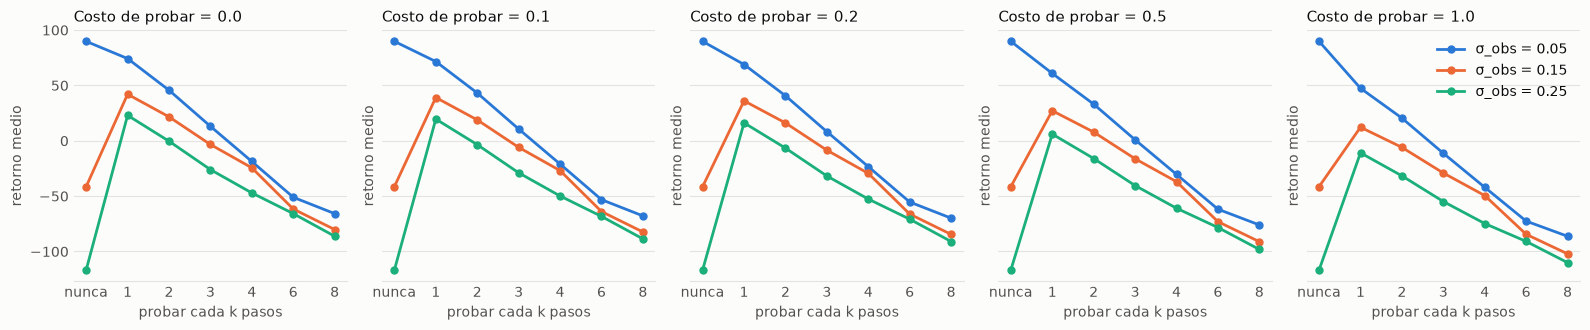

In [4]:
calibrate.plot_taste_sweep(sweep, out_dir=FIGURES);

## 3. Tamaño por defecto de la ventana visible N

Se corre la FIFO en la cocina randomizada y se mide cuántas órdenes esperan en la cola en cada paso. El N por defecto es el menor que cubre la cola en al menos el 90 % de los pasos. La ablación de N (1, 2, 4, 6) se hace alrededor de este valor.

N por defecto (cuantil 0.9): 7


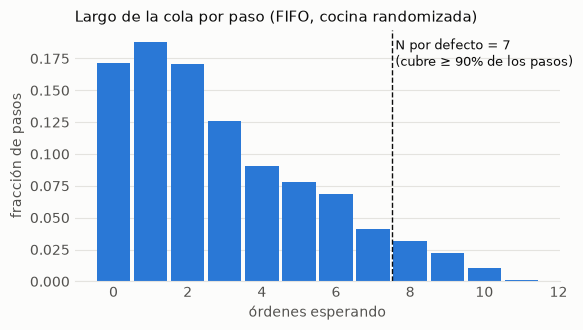

In [5]:
lengths = calibrate.queue_lengths(n_episodes=EPISODES)
lengths.to_csv(TABLES / "calibration_queue_lengths.csv", index=False)
print("N por defecto (cuantil 0.9):", calibrate.default_window(lengths))
calibrate.plot_queue_lengths(lengths, out_dir=FIGURES);

## 4. ¿Priorizar importa?

Comparamos la FIFO (solo atiende la orden más antigua) con dos heurísticas que eligen orden:

- **EDF:** la hora de entrega más próxima, adelantando preparación.
- **Triage:** ignora las órdenes que ya no alcanzan a salir, atiende primero las que aún llegan a tiempo y, entre ellas, la que pide menos preparación.

Ninguna es un baseline del reporte: solo verifican que el ambiente premia elegir bien. Si ninguna supera claramente a la FIFO, la pregunta central del proyecto (¿aprenden los agentes a priorizar?) no tendría respuesta y habría que ajustar los platos o las horas de entrega.

In [6]:
prio = calibrate.prioritization_check(n_episodes=EPISODES)
prio.to_csv(TABLES / "calibration_prioritization.csv", index=False)
prio.groupby(["scenario", "policy"], sort=False)[["return", "on_time_rate", "expired_rate"]].agg(["mean", "std"]).round(3)

return         on_time_rate        expired_rate       
                    mean     std         mean    std         mean    std
scenario policy                                                         
random   fifo      4.167  69.460        0.428  0.205        0.405  0.183
hard     fifo   -145.878  47.049        0.125  0.063        0.709  0.086
random   edf      -3.651  81.780        0.404  0.225        0.431  0.219
hard     edf    -157.773  56.484        0.114  0.068        0.752  0.115
random   triage   73.943  47.487        0.637  0.129        0.297  0.136
hard     triage  -16.590  37.203        0.402  0.069        0.523  0.064

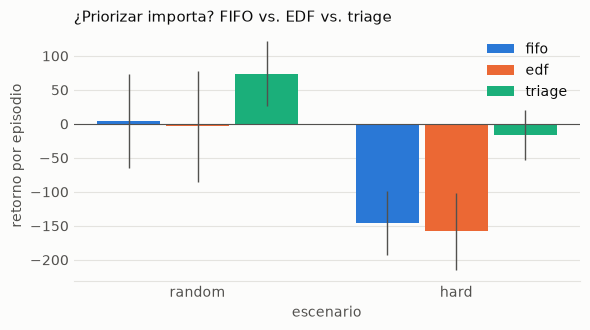

In [7]:
calibrate.plot_prioritization(prio, out_dir=FIGURES);

## 5. Dificultad

La FIFO debe superar claramente a la aleatoria (el ambiente no se resuelve solo) y **no** estar cerca de 100 % a tiempo (debe quedar margen para que el RL mejore).

In [8]:
diff = calibrate.difficulty_check(n_episodes=EPISODES)
diff.to_csv(TABLES / "calibration_difficulty.csv", index=False)
diff.groupby(["scenario", "policy"], sort=False)[["return", "on_time_rate", "expired_rate"]].mean().round(3)

,,return,on_time_rate,expired_rate
scenario,policy,,,
random,random,-174.662,0.006,0.886
easy,random,-105.363,0.004,0.869
medium,random,-169.242,0.003,0.891
hard,random,-258.157,0.000,0.927
low_noise,random,-169.242,0.003,0.891
high_noise,random,-169.242,0.003,0.891
single_station,random,-169.153,0.003,0.897
random,fifo,4.167,0.428,0.405
easy,fifo,84.517,0.812,0.068


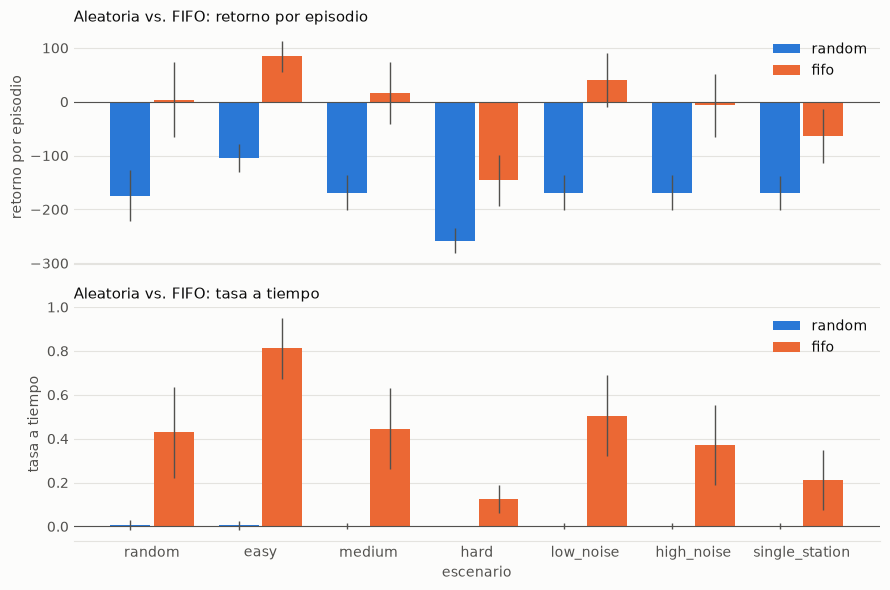

In [9]:
calibrate.plot_difficulty(diff, out_dir=FIGURES);

## Conclusiones

Resultados con 50 episodios por configuración, en las seeds de validación. Los valores elegidos están registrados en `docs/env_design.md`, sección 10.

| Criterio | Resultado | Estado |
|---|---|---|
| 1. Costo de probar | La mejor frecuencia nunca queda en medio | No se cumple tal como estaba planteado |
| 2. Rango de σ_obs | Los extremos se comportan de forma opuesta | Se cumple |
| 3. N por defecto | El cuantil 0.9 da N = 7; N = 6 cubre el 89.2 % | Se usa N = 6 |
| 4. Priorizar importa | La EDF no supera a la FIFO; la triage sí, con amplio margen | Se cumple |
| 5. Dificultad | La FIFO supera a la aleatoria y deja margen | Se cumple |

**1. Costo de probar.** En las 15 combinaciones de costo y ruido la mejor *k* fue un extremo: "nunca" con σ_obs = 0.05 y *k* = 1 con σ_obs = 0.15 y 0.25. Ningún costo entre 0 y 1 cambia ese resultado, así que el costo no es lo que decide. La causa está en el barrido: la heurística empieza a probar cuando el plato "se ve" casi listo, de modo que espaciar las pruebas casi no ahorra pruebas y sí deja pasar la ventana de los platos rápidos.

El propósito del criterio (que probar sea una decisión real) sí se cumple, por otra vía: lo que conviene se invierte con el ruido. Con costo 0.2, a σ_obs = 0.05 no probar supera a *k* = 1 (89.8 contra 68.9), y a σ_obs = 0.25 probar en cada paso supera por mucho a no probar (16.2 contra −116.7). Como el ruido se sortea en cada episodio y no se observa, el agente tiene que adaptar cuánto prueba. **Se mantiene el costo de 0.2.**

**2. Ruido visual.** A σ_obs = 0.05 la vista casi alcanza y a 0.25 ya no sirve: sin probar, el retorno cae de 89.8 a −116.7. **Se mantiene el rango [0.05, 0.25].**

**3. N por defecto.** El menor N que cubre al menos el 90 % de los pasos es 7, pero N = 6 cubre el 89.2 %. Agregar N = 7 costaría 10 corridas más por una diferencia de menos de un punto, así que **se usa N = 6** y la grilla queda en {1, 2, 4, 6}. Además, esta medición usa la FIFO, que acumula cola: un agente que prioriza debería tener colas más cortas.

**4. Priorizar importa.** Diferencia de retorno contra la FIFO, con episodios pareados e IC 95 % por bootstrap:

| Escenario | EDF − FIFO | Triage − FIFO |
|---|---|---|
| Cocina randomizada | −7.8 [−19.5, 3.5] | **+69.8 [50.9, 89.1]** |
| Difícil | −11.9 [−19.2, −4.0] | **+129.3 [117.8, 141.2]** |

La EDF pura no mejora a la FIFO: con la cocina saturada gasta su tiempo en las órdenes más atrasadas, que de todos modos expiran. La triage, que ignora las órdenes que ya no se salvan, sí la supera claramente, así que **el ambiente premia elegir bien** y la pregunta central del proyecto tiene respuesta. Es una verificación de que existe margen, no un baseline: se eligió después de probar varias reglas sobre estas mismas seeds de validación, y no se usa en el reporte.

**5. Dificultad.** En la cocina randomizada la FIFO logra 4.2 de retorno y 42.8 % a tiempo, contra −174.7 y 0.6 % de la aleatoria. Va de 81.2 % a tiempo en `easy` a 12.5 % en `hard`, lejos del 100 %, así que queda margen para el RL. Con una sola estación la FIFO aún entrega 21.2 % a tiempo y supera a la aleatoria (−63.9 contra −169.2), por lo que K = 1 **queda validado como escenario fuera de distribución.**